# Preparation

In [2]:
from pathlib import Path
import subprocess
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error as mae

# Data Collection

In [3]:
USER = "madhurima2904"
REPO = "DS603_project"
REPO_DIR = Path(REPO)                      # relative to the current working directory

if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", f"https://github.com/{USER}/{REPO}.git", str(REPO_DIR)],
        check=True,
    )

DATA = REPO_DIR / "data" / "raw"           # relative path to the raw data
print(DATA.is_dir(), [p.name for p in DATA.iterdir()])


Cloning into 'DS603_project'...


True ['us_macro_1990_2026_monthly.xlsx', 'historial_data_for_hy_oas.csv']


In [4]:
df_hy = pd.read_csv(DATA / "historial_data_for_hy_oas.csv", parse_dates=["Date"])
df_hy.head()

,Date,Value
0,1996-12-31,3.61
1,1997-01-02,3.51
2,1997-01-03,3.54
3,1997-01-06,3.55
4,1997-01-07,3.56


In [5]:
df_macro = pd.read_excel(DATA / "us_macro_1990_2026_monthly.xlsx", parse_dates=["Month"])
df_macro.head()

,Month,Real_GDP_bn_2017$_(Q),Fed_Funds_Rate_%,Unemployment_Rate_%,Consumer Price Index for All Urban Consumers,WTI_Oil_USD_bbl,Global_Commodity_Index
0,1990-01-01,10047.386,8.23,5.4,127.5,22.863182,NaN
1,1990-02-01,10047.386,8.24,5.3,128.0,22.113000,NaN
2,1990-03-01,10047.386,8.28,5.2,128.6,20.387727,NaN
3,1990-04-01,10083.855,8.26,5.4,128.9,18.425500,NaN
4,1990-05-01,10083.855,8.18,5.4,129.1,18.303333,NaN


# Data Cleaning

In [6]:
print(df_hy.shape)
print(df_macro.shape)

(7770, 2)
(442, 7)


In [7]:
df_hy["Date"] = pd.to_datetime(df_hy["Date"])
print("Start Date:", df_hy["Date"].min().strftime("%Y-%m-%d"))
print("End Date:", df_hy["Date"].max().strftime("%Y-%m-%d"))

Start Date: 1996-12-31
End Date: 2026-10-01


In [8]:
df_macro["Month"] = pd.to_datetime(df_macro["Month"])
print("Start Date:", df_macro["Month"].min().strftime("%Y-%m-%d"))
print("End Date:", df_macro["Month"].max().strftime("%Y-%m-%d"))

Start Date: 1990-01-01
End Date: 2026-10-01


In [9]:
#Keeping data from Dec 1998 to Dec 2025
df_hy = df_hy[(df_hy["Date"] >= "1998-12-01") & (df_hy["Date"] <= "2026-06-30")]
df_macro = df_macro[(df_macro["Month"]>= "1998-12-01") & (df_macro["Month"] <= "2026-06-30")]

In [10]:
#Checking for missing values
df_hy.isnull().sum()

Date     0
Value    0
dtype: int64

In [11]:
df_macro.isnull().sum()

Month                                           0
Real_GDP_bn_2017$_(Q)                           2
Fed_Funds_Rate_%                                0
Unemployment_Rate_%                             1
Consumer Price Index for All Urban Consumers    1
WTI_Oil_USD_bbl                                 0
Global_Commodity_Index                          0
dtype: int64

In [12]:
# Forward fill missing values (propagate last valid observation forward)
df_macro = df_macro.ffill()

In [13]:
#aggregate to monthly by taking the last value for that month

df_hy = df_hy.resample("MS", on="Date")["Value"].last().reset_index()
df_hy = df_hy.rename(columns={'Value': 'S_t'})

print(df_hy.round(2))

          Date   S_t
0   1998-12-01  5.89
1   1999-01-01  5.76
2   1999-02-01  5.21
3   1999-03-01  4.90
4   1999-04-01  4.55
..         ...   ...
326 2026-02-01  3.45
327 2026-03-01  3.61
328 2026-04-01  3.11
329 2026-05-01  2.99
330 2026-06-01  2.99

[331 rows x 2 columns]


/var/folders/01/vqr4c10j7858g1_gl16xw9q00000gn/T/ipykernel_82165/433498313.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(df_hy.round(2))


In [14]:
df_hy.info()

<class 'pandas.DataFrame'>
RangeIndex: 331 entries, 0 to 330
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    331 non-null    datetime64[us]
 1   S_t     331 non-null    float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 5.3 KB


## Merge Macro data with HY_OAS data

In [15]:
df_hy["YearMonth"] = df_hy["Date"].dt.to_period("M")
df_macro["YearMonth"] = df_macro["Month"].dt.to_period("M")
merged_df = pd.merge(df_macro, df_hy, on="YearMonth", how="left")

#Dropped columns here
merged_df.drop(columns=["YearMonth", "WTI_Oil_USD_bbl","Real_GDP_bn_2017$_(Q)", "Date"], inplace=True)
merged_df.rename({
    "Fed_Funds_Rate_%": "Fed_Rate%",
    "Unemployment_Rate_%": "Unemp_Rate%",
    "Consumer Price Index for All Urban Consumers":"CPI",
    "Global_Commodity_Index": "GCI"},axis = 1,inplace = True)
merged_df.head()

/var/folders/01/vqr4c10j7858g1_gl16xw9q00000gn/T/ipykernel_82165/890440040.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  merged_df.drop(columns=["YearMonth", "WTI_Oil_USD_bbl","Real_GDP_bn_2017$_(Q)", "Date"], inplace=True)
/var/folders/01/vqr4c10j7858g1_gl16xw9q00000gn/T/ipykernel_82165/890440040.py:7: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  merged_df.rename({


,Month,Fed_Rate%,Unemp_Rate%,CPI,GCI,S_t
0,1998-12-01,4.68,4.4,164.4,43.065277,5.89
1,1999-01-01,4.63,4.3,164.7,43.939839,5.76
2,1999-02-01,4.76,4.4,164.7,42.153610,5.21
3,1999-03-01,4.81,4.2,164.8,43.341471,4.90
4,1999-04-01,4.74,4.3,165.9,45.841843,4.55


In [16]:
print("Start Date:", merged_df["Month"].min().strftime("%Y-%m-%d"))
print("End Date:", merged_df["Month"].max().strftime("%Y-%m-%d"))
print('________________________________________________________')
print(merged_df.info())

Start Date: 1998-12-01
End Date: 2026-06-01
________________________________________________________
<class 'pandas.DataFrame'>
RangeIndex: 331 entries, 0 to 330
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Month        331 non-null    datetime64[us]
 1   Fed_Rate%    331 non-null    float64       
 2   Unemp_Rate%  331 non-null    float64       
 3   CPI          331 non-null    float64       
 4   GCI          331 non-null    float64       
 5   S_t          331 non-null    float64       
dtypes: datetime64[us](1), float64(5)
memory usage: 15.6 KB
None


#Feature Engineering

## Calculate 6-month shift `S_{t+6}`

In [17]:
merged_df = merged_df.sort_values("Month")

merged_df["S_{t+6}"] = merged_df["S_t"].shift(-6)
print(merged_df[["Month", "S_t", "S_{t+6}"]].tail(15))

         Month   S_t  S_{t+6}
316 2025-04-01  4.11     3.07
317 2025-05-01  3.51     3.05
318 2025-06-01  3.05     3.01
319 2025-07-01  2.98     3.14
320 2025-08-01  2.98     3.45
321 2025-09-01  2.83     3.61
322 2025-10-01  3.07     3.11
323 2025-11-01  3.05     2.99
324 2025-12-01  3.01     2.99
325 2026-01-01  3.14      NaN
326 2026-02-01  3.45      NaN
327 2026-03-01  3.61      NaN
328 2026-04-01  3.11      NaN
329 2026-05-01  2.99      NaN
330 2026-06-01  2.99      NaN


## One-month change in the spread `S_t - S_{t-1}`

In [18]:
merged_df['S_t - S_{t-1}'] = merged_df['S_t'].diff()
merged_df.head()

,Month,Fed_Rate%,Unemp_Rate%,CPI,GCI,S_t,S_{t+6},S_t - S_{t-1}
0,1998-12-01,4.68,4.4,164.4,43.065277,5.89,4.76,NaN
1,1999-01-01,4.63,4.3,164.7,43.939839,5.76,4.76,-0.13
2,1999-02-01,4.76,4.4,164.7,42.153610,5.21,5.00,-0.55
3,1999-03-01,4.81,4.2,164.8,43.341471,4.90,5.33,-0.31
4,1999-04-01,4.74,4.3,165.9,45.841843,4.55,5.00,-0.35


## Target Variable `S_{t+6} - S_t`

In [19]:
merged_df["S_{t+6} - S_t"] = merged_df["S_{t+6}"].sub(merged_df["S_t"], axis=0)
merged_df.head()

,Month,Fed_Rate%,Unemp_Rate%,CPI,GCI,S_t,S_{t+6},S_t - S_{t-1},S_{t+6} - S_t
0,1998-12-01,4.68,4.4,164.4,43.065277,5.89,4.76,NaN,-1.13
1,1999-01-01,4.63,4.3,164.7,43.939839,5.76,4.76,-0.13,-1.00
2,1999-02-01,4.76,4.4,164.7,42.153610,5.21,5.00,-0.55,-0.21
3,1999-03-01,4.81,4.2,164.8,43.341471,4.90,5.33,-0.31,0.43
4,1999-04-01,4.74,4.3,165.9,45.841843,4.55,5.00,-0.35,0.45


## YoY change for CPI and GCI

In [20]:
merged_df["CPI_yoy"] = (merged_df["CPI"].pct_change(12, fill_method=None) * 100)
merged_df["GCI_yoy"] = (merged_df["GCI"].pct_change(12, fill_method=None) * 100)
merged_df.head()

,Month,Fed_Rate%,Unemp_Rate%,CPI,GCI,S_t,S_{t+6},S_t - S_{t-1},S_{t+6} - S_t,CPI_yoy,GCI_yoy
0,1998-12-01,4.68,4.4,164.4,43.065277,5.89,4.76,NaN,-1.13,NaN,NaN
1,1999-01-01,4.63,4.3,164.7,43.939839,5.76,4.76,-0.13,-1.00,NaN,NaN
2,1999-02-01,4.76,4.4,164.7,42.153610,5.21,5.00,-0.55,-0.21,NaN,NaN
3,1999-03-01,4.81,4.2,164.8,43.341471,4.90,5.33,-0.31,0.43,NaN,NaN
4,1999-04-01,4.74,4.3,165.9,45.841843,4.55,5.00,-0.35,0.45,NaN,NaN


## 1 month lag of macro variables

In [21]:
merged_df["Fed_Rate%_L1"] = merged_df["Fed_Rate%"].shift(1)
merged_df["Unemp_Rate%_L1"] = merged_df["Unemp_Rate%"].shift(1)
merged_df["CPI_yoy_L1"] = merged_df["CPI_yoy"].shift(1)
merged_df["GCI_yoy_L1"] = merged_df["GCI_yoy"].shift(1)
merged_df.head()

,Month,Fed_Rate%,Unemp_Rate%,CPI,GCI,S_t,S_{t+6},S_t - S_{t-1},S_{t+6} - S_t,CPI_yoy,GCI_yoy,Fed_Rate%_L1,Unemp_Rate%_L1,CPI_yoy_L1,GCI_yoy_L1
0,1998-12-01,4.68,4.4,164.4,43.065277,5.89,4.76,NaN,-1.13,NaN,NaN,NaN,NaN,NaN,NaN
1,1999-01-01,4.63,4.3,164.7,43.939839,5.76,4.76,-0.13,-1.00,NaN,NaN,4.68,4.4,NaN,NaN
2,1999-02-01,4.76,4.4,164.7,42.153610,5.21,5.00,-0.55,-0.21,NaN,NaN,4.63,4.3,NaN,NaN
3,1999-03-01,4.81,4.2,164.8,43.341471,4.90,5.33,-0.31,0.43,NaN,NaN,4.76,4.4,NaN,NaN
4,1999-04-01,4.74,4.3,165.9,45.841843,4.55,5.00,-0.35,0.45,NaN,NaN,4.81,4.2,NaN,NaN


TIME PERIOD

In [22]:
#Keeping Data only from Jan 2000 to June 2026 for modelling
merged_df = merged_df[(merged_df["Month"] >= "2000-01-01") & (merged_df["Month"]< "2026-01-01")]
print("Start Date:", merged_df["Month"].min().strftime("%Y-%m-%d"))
print("End Date:", merged_df["Month"].max().strftime("%Y-%m-%d"))

Start Date: 2000-01-01
End Date: 2025-12-01


In [23]:
#Validation
merged_df.isna().sum()

Month             0
Fed_Rate%         0
Unemp_Rate%       0
CPI               0
GCI               0
S_t               0
S_{t+6}           0
S_t - S_{t-1}     0
S_{t+6} - S_t     0
CPI_yoy           0
GCI_yoy           0
Fed_Rate%_L1      0
Unemp_Rate%_L1    0
CPI_yoy_L1        0
GCI_yoy_L1        0
dtype: int64

# Train_Test_split

**Predictor set**
1. current OAS level `(S_t)`,
2. previous one-month change `(S_t-S_{t-1})`,
3. broad commodity-index change `GCI_yoy_L1`,
4. federal funds rate `Fed_Rate%_L1`,
5. unemployment rate `Unemp_Rate%_L1`,
6. year-on-year CPI inflation `CPI_yoy_L1`

**Target**
6 month change in spread: `S_{t+6} - S_t`

In [24]:
X_cols = ["Month",
    "S_t",
    "S_t - S_{t-1}",
    "GCI_yoy_L1",
    "Fed_Rate%_L1",
    "Unemp_Rate%_L1",
    "CPI_yoy_L1"
]

y = merged_df["S_{t+6} - S_t"]
X = merged_df[X_cols]

print(y.shape)
print(X.shape)

(312,)
(312, 7)


## Split data into train and test

In [25]:
train_mask = (merged_df["Month"] >= "2000-01-01") & (
    merged_df["Month"] <= "2022-06-01"
)

test_mask = (merged_df["Month"] >= "2023-01-01") & (
    merged_df["Month"] <= "2025-12-01"
)

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

X_train = X_train.copy()
X_test = X_test.copy()

X_train["Month"] = merged_df.loc[train_mask, "Month"]
X_test["Month"] = merged_df.loc[test_mask, "Month"]

# Data Visualisation

## Plots

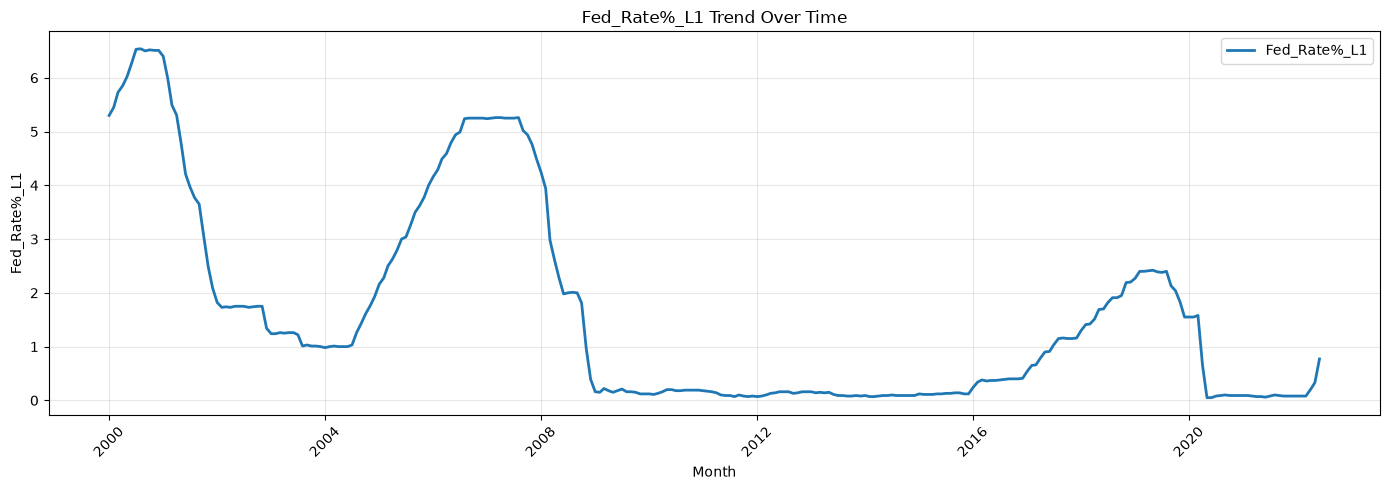

/var/folders/01/vqr4c10j7858g1_gl16xw9q00000gn/T/ipykernel_82165/2064630325.py:32: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


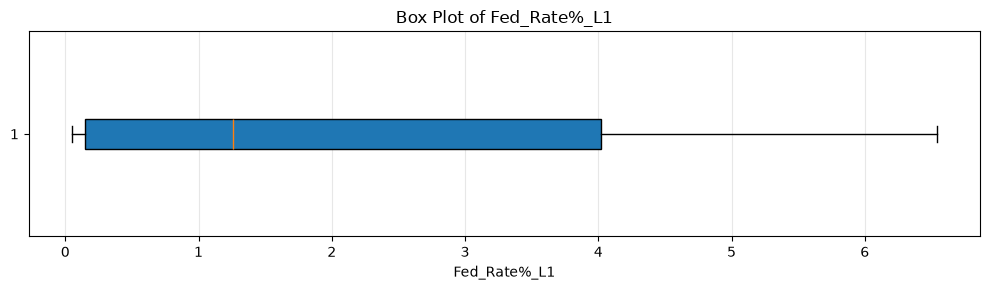

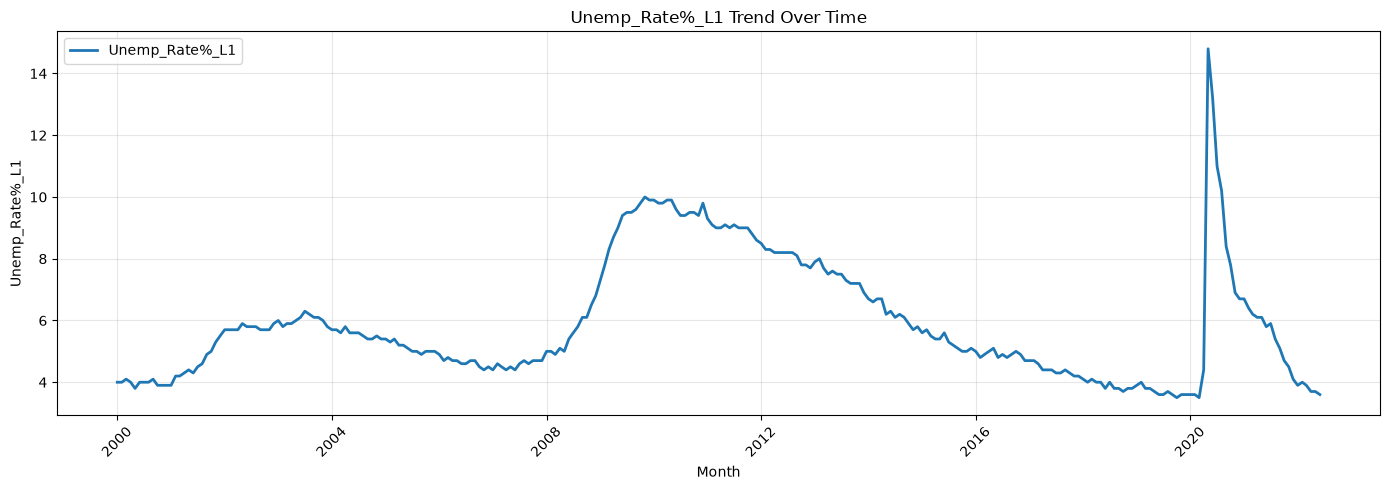

/var/folders/01/vqr4c10j7858g1_gl16xw9q00000gn/T/ipykernel_82165/2064630325.py:32: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


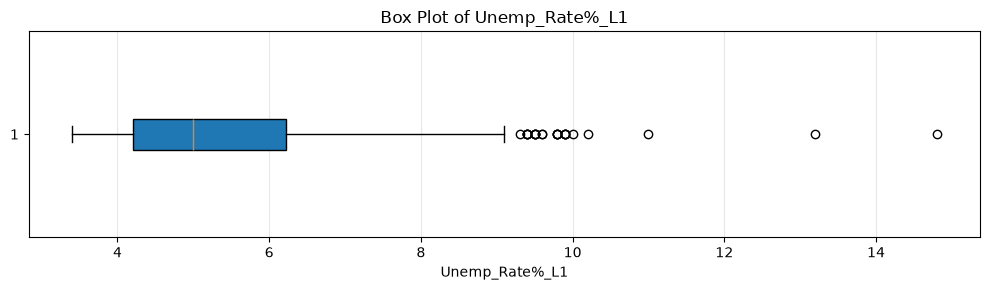

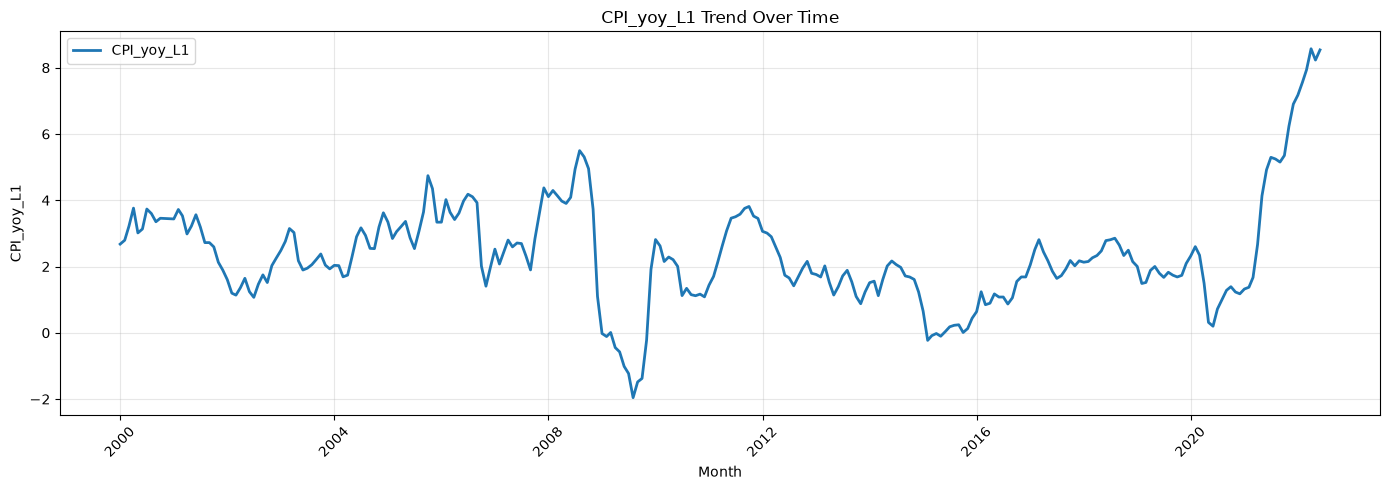

/var/folders/01/vqr4c10j7858g1_gl16xw9q00000gn/T/ipykernel_82165/2064630325.py:32: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


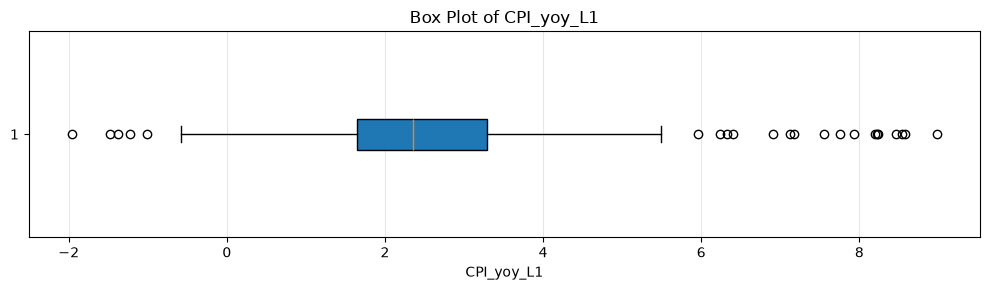

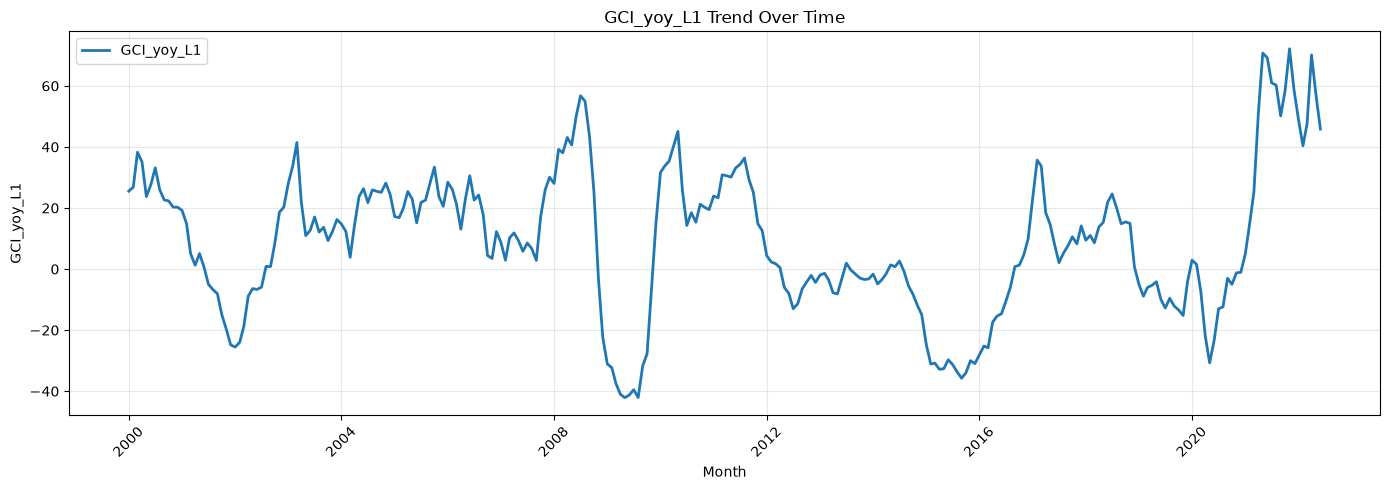

/var/folders/01/vqr4c10j7858g1_gl16xw9q00000gn/T/ipykernel_82165/2064630325.py:32: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


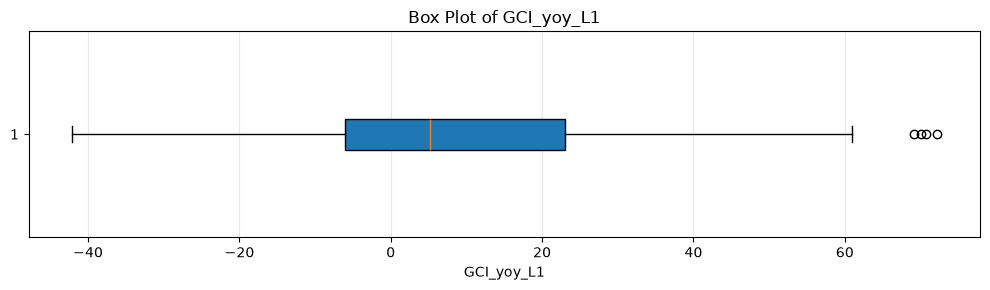

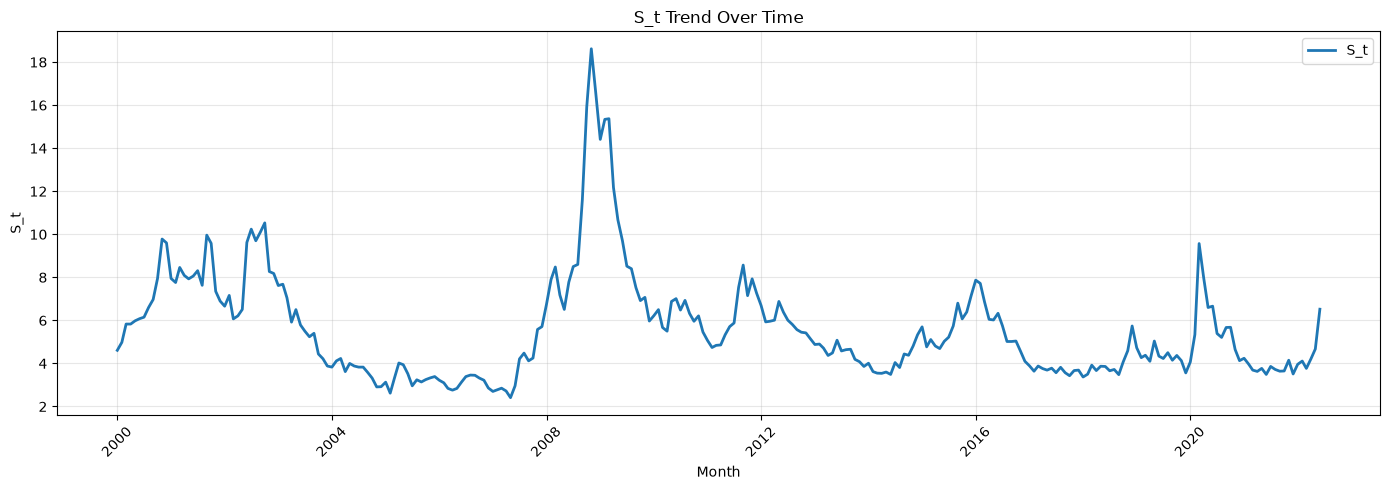

/var/folders/01/vqr4c10j7858g1_gl16xw9q00000gn/T/ipykernel_82165/2064630325.py:32: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


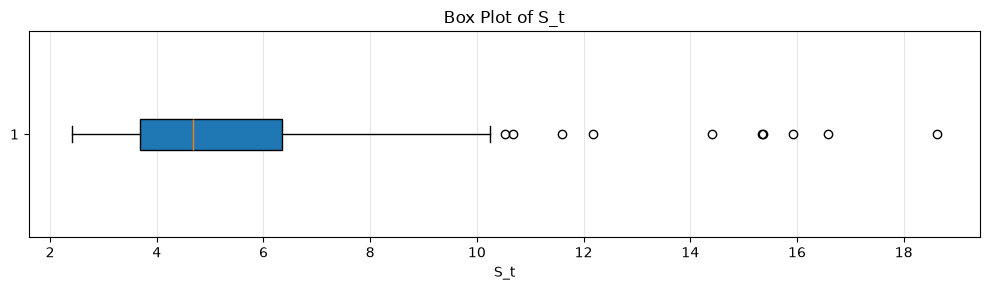

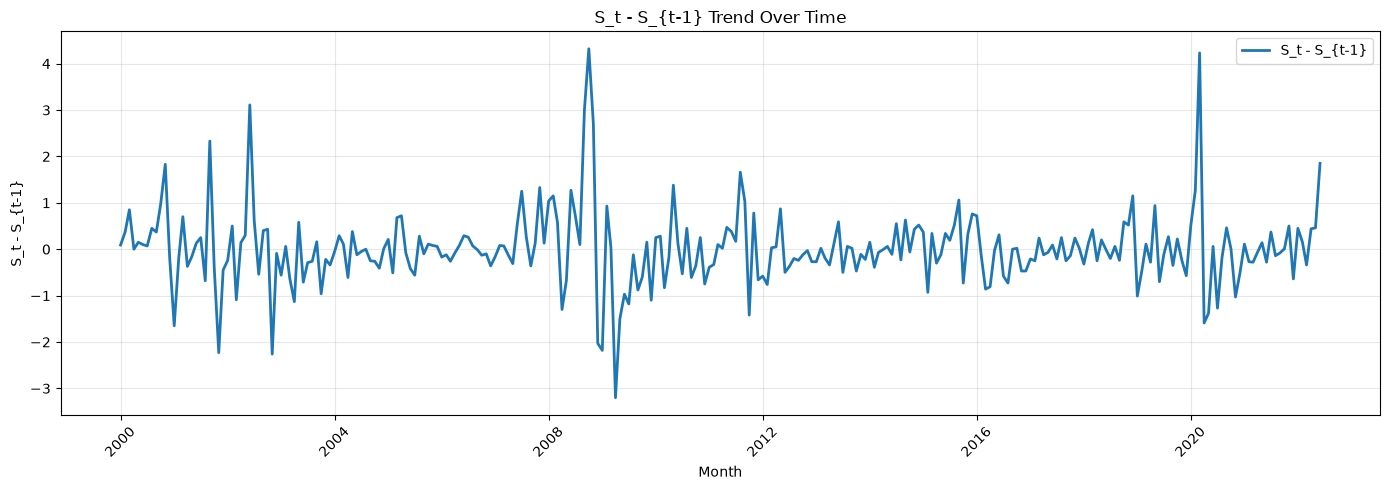

/var/folders/01/vqr4c10j7858g1_gl16xw9q00000gn/T/ipykernel_82165/2064630325.py:32: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


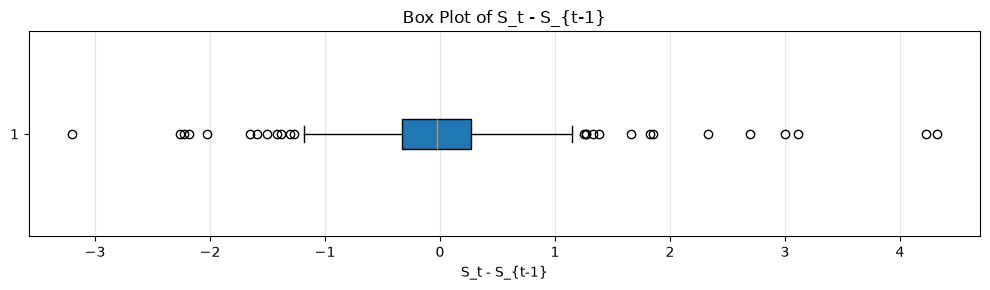

In [26]:
variables = [
    "Fed_Rate%_L1",
    "Unemp_Rate%_L1",
    "CPI_yoy_L1",
    "GCI_yoy_L1",
    "S_t",
    "S_t - S_{t-1}"
]

for col in variables:

    plt.figure(figsize=(14, 5))

    plt.plot(
        X_train["Month"],
        X_train[col],
        linewidth=2,
        label=col
    )

    plt.title(f"{col} Trend Over Time")
    plt.xlabel("Month")
    plt.ylabel(col)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 3))

    plt.boxplot(
        merged_df[col],
        vert=False,
        patch_artist=True
    )

    plt.title(f"Box Plot of {col}")
    plt.xlabel(col)
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

## Histogram

### Monthly Change (S_t - S_{t-1})

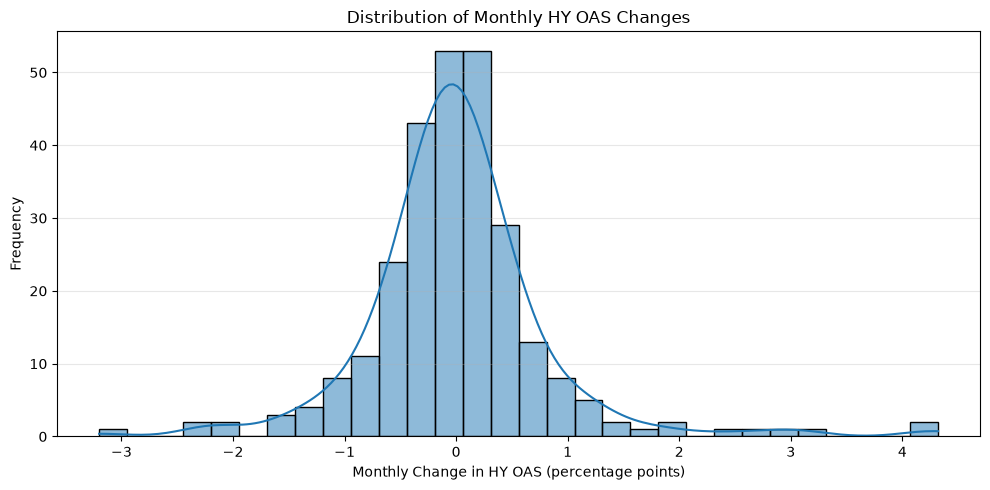

In [27]:
plt.figure(figsize=(10, 5))

sns.histplot(
    X_train["S_t - S_{t-1}"].dropna(),
    bins=30,
    kde=True
)

plt.title("Distribution of Monthly HY OAS Changes")
plt.xlabel("Monthly Change in HY OAS (percentage points)")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


The distribution is centred at about 0 with a tall, sharp peak. The two tallest bins (about 70 and 60 months) sit within ±0.3 pp.
The tails are long and thin. Isolated bars reach about −3 on the left and +4.3 on the right, far from the bulk.
The overlaid smooth curve shows a peaked, fat-tailed shape. A Normal curve would be lower at the peak and place almost no mass at ±3–4 pp.
It’s mildly right-skewed. The largest outliers are widenings (+4.3 vs about −3.2), which a symmetric model can’t capture.
This is the motivation for comparing Normal and Student-t. The fitted ν ≈ 2.1 says the tails are very heavy.

### 6-Monthly Change (S_{t+6} - S_t)

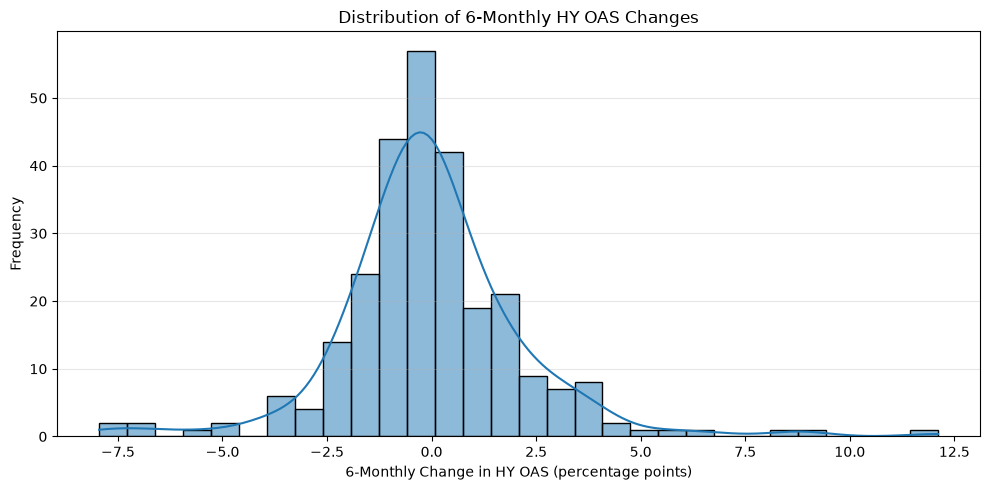

In [28]:
plt.figure(figsize=(10, 5))

sns.histplot(
    y_train.dropna(),
    bins=30,
    kde=True
)

plt.title("Distribution of 6-Monthly HY OAS Changes")
plt.xlabel("6-Monthly Change in HY OAS (percentage points)")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


##Scatter Plots

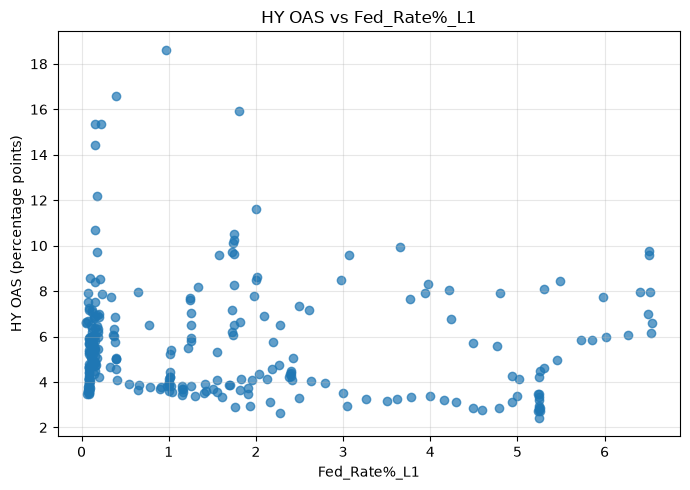

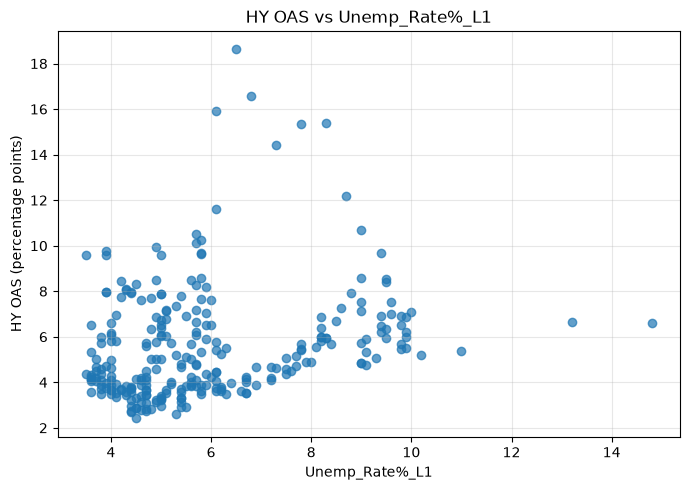

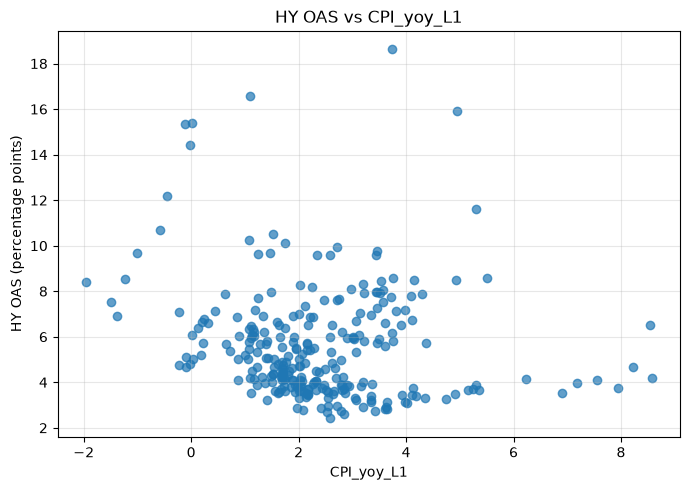

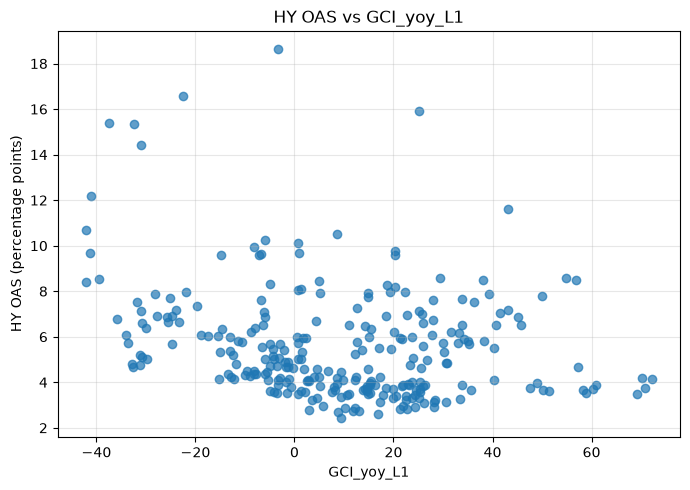

In [29]:
macro_vars = [
    "Fed_Rate%_L1",
    "Unemp_Rate%_L1",
    "CPI_yoy_L1",
    "GCI_yoy_L1"
]

for col in macro_vars:
    temp = X_train[[col, "S_t"]].dropna()

    plt.figure(figsize=(7, 5))

    plt.scatter(
        temp[col],
        temp["S_t"],
        alpha=0.7
    )

    plt.title(f"HY OAS vs {col}")
    plt.xlabel(col)
    plt.ylabel("HY OAS (percentage points)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## Correlation

In [30]:
X_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 270 entries, 13 to 282
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Month           270 non-null    datetime64[us]
 1   S_t             270 non-null    float64       
 2   S_t - S_{t-1}   270 non-null    float64       
 3   GCI_yoy_L1      270 non-null    float64       
 4   Fed_Rate%_L1    270 non-null    float64       
 5   Unemp_Rate%_L1  270 non-null    float64       
 6   CPI_yoy_L1      270 non-null    float64       
dtypes: datetime64[us](1), float64(6)
memory usage: 14.9 KB


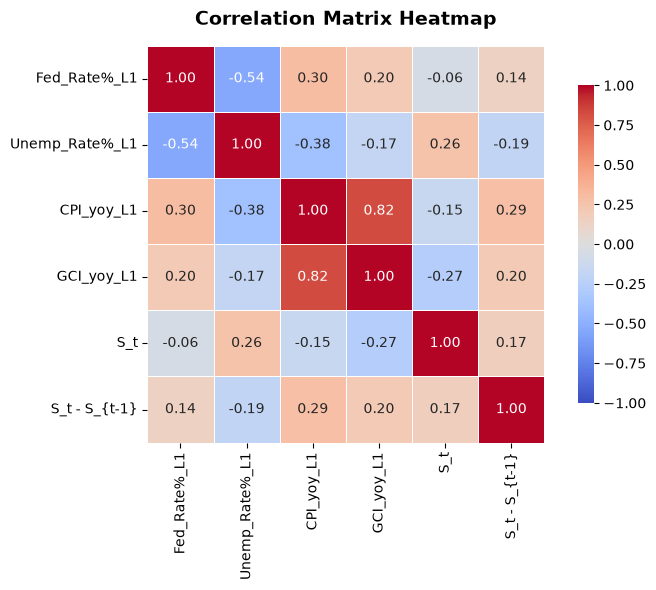

In [31]:
cols = ["Fed_Rate%_L1", "Unemp_Rate%_L1", "CPI_yoy_L1", "GCI_yoy_L1", "S_t","S_t - S_{t-1}"]
corr_matrix = X_train[cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,  # Display correlation numbers inside cells
    fmt=".2f",  # Format numbers to 2 decimal places
    cmap="coolwarm",  # Red-blue color map (red = positive, blue = negative)
    vmin=-1,
    vmax=1,  # Set color bar limits from -1 to 1
    square=True,  # Force square cells
    linewidths=0.5,  # Add subtle grid line dividers
    cbar_kws={"shrink": 0.8},
)

plt.title("Correlation Matrix Heatmap", fontsize=14, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

# Distribution for One-month change of HY_OAS



## One-month change in the spread

In [32]:
df = X_train.copy()
dS = df[["Month", "S_t - S_{t-1}"]]
dS = dS.dropna()
print(dS.head())

        Month  S_t - S_{t-1}
13 2000-01-01           0.09
14 2000-02-01           0.37
15 2000-03-01           0.85
16 2000-04-01           0.00
17 2000-05-01           0.15


## Visualisation for One-month change of HY_OAS


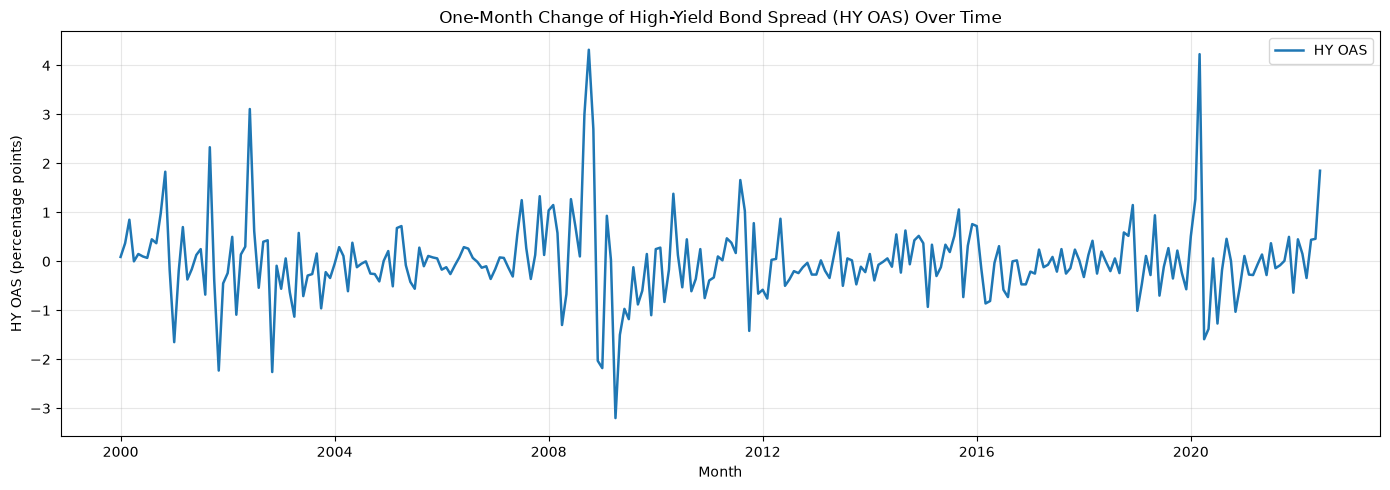

In [33]:
plt.figure(figsize=(14, 5))

plt.plot(dS["Month"],
    dS["S_t - S_{t-1}"],
    color="C0",
    linewidth=1.8,
    label="HY OAS"
)

plt.title("One-Month Change of High-Yield Bond Spread (HY OAS) Over Time")
plt.xlabel("Month")
plt.ylabel("HY OAS (percentage points)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [34]:
# Fit Normal and Student-t only on training data

mu_n, sd_n = stats.norm.fit(dS['S_t - S_{t-1}'])
nu_t, loc_t, scale_t = stats.t.fit(dS['S_t - S_{t-1}'])

print(f"Normal   : mu={mu_n:.4f}, sigma={sd_n:.4f}")
print(f"Student-t: nu={nu_t:.2f}, loc={loc_t:.4f}, scale={scale_t:.4f}")

Normal   : mu=0.0074, sigma=0.8185
Student-t: nu=2.12, loc=-0.0334, scale=0.4030


The Normal fit gives a mean of about zero (0.0074) and a standard deviation of 0.8185, while the Student-t gives a location of -0.0334, a scale of 0.4 and ν = 2.12. The center is near zero in both, so there is no meaningful drift in monthly OAS changes. The very low ν, barely above 2, signals extremely fat tails and the Normal’s σ is inflated by a few crisis months, so the t’s smaller scale better describes a typical month.

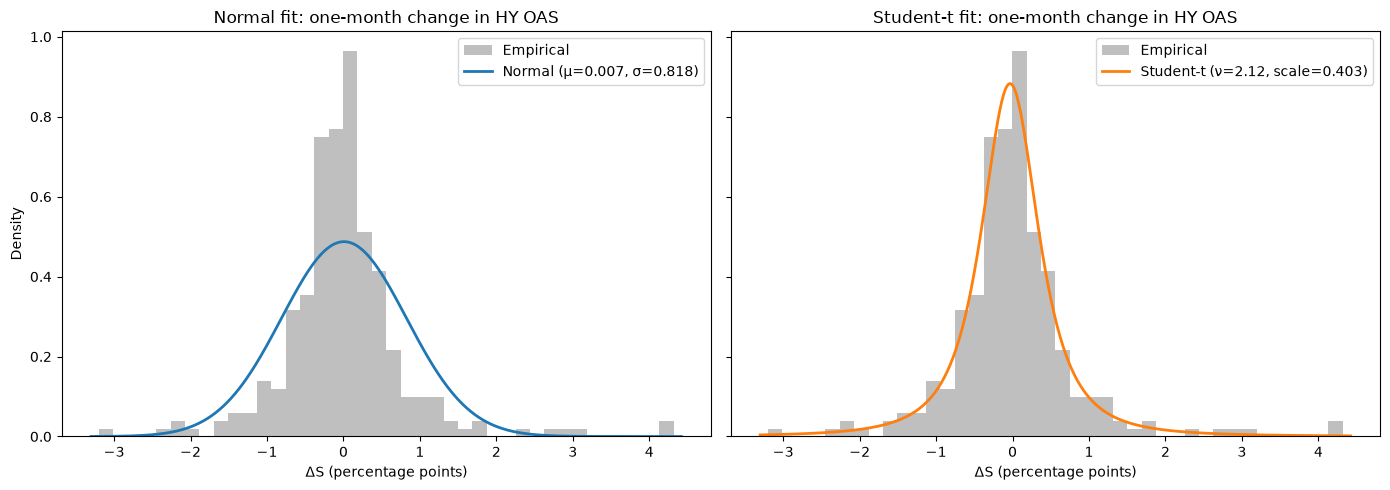

In [35]:
x = np.linspace(dS["S_t - S_{t-1}"].min() - 0.1, dS["S_t - S_{t-1}"].max() + 0.1, 600)

fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Normal
ax[0].hist(dS["S_t - S_{t-1}"], bins=40, density=True, alpha=0.5, color="grey", label="Empirical")
ax[0].plot(x, stats.norm.pdf(x, mu_n, sd_n), color="C0", lw=2,
           label=f"Normal (μ={mu_n:.3f}, σ={sd_n:.3f})")
ax[0].set_title("Normal fit: one-month change in HY OAS")
ax[0].set_xlabel("ΔS (percentage points)")
ax[0].set_ylabel("Density")
ax[0].legend()

# Student-t
ax[1].hist(dS["S_t - S_{t-1}"], bins=40, density=True, alpha=0.5, color="grey", label="Empirical")
ax[1].plot(x, stats.t.pdf(x, nu_t, loc_t, scale_t), color="C1", lw=2,
           label=f"Student-t (ν={nu_t:.2f}, scale={scale_t:.3f})")
ax[1].set_title("Student-t fit: one-month change in HY OAS")
ax[1].set_xlabel("ΔS (percentage points)")
ax[1].legend()

plt.tight_layout()
plt.show()

Most monthly changes cluster tightly around zero, with a tall, sharp peak and a handful of outliers out to about -3 and +4 pp. The Normal curve is too low at the peak and too wide in the shoulders, so it misrepresents both the ordinary months and the extremes. The Student-t curve tracks the peak height and the long tails closely, making it visibly the better fit.

### Q–Q plots: Normal vs Student-t

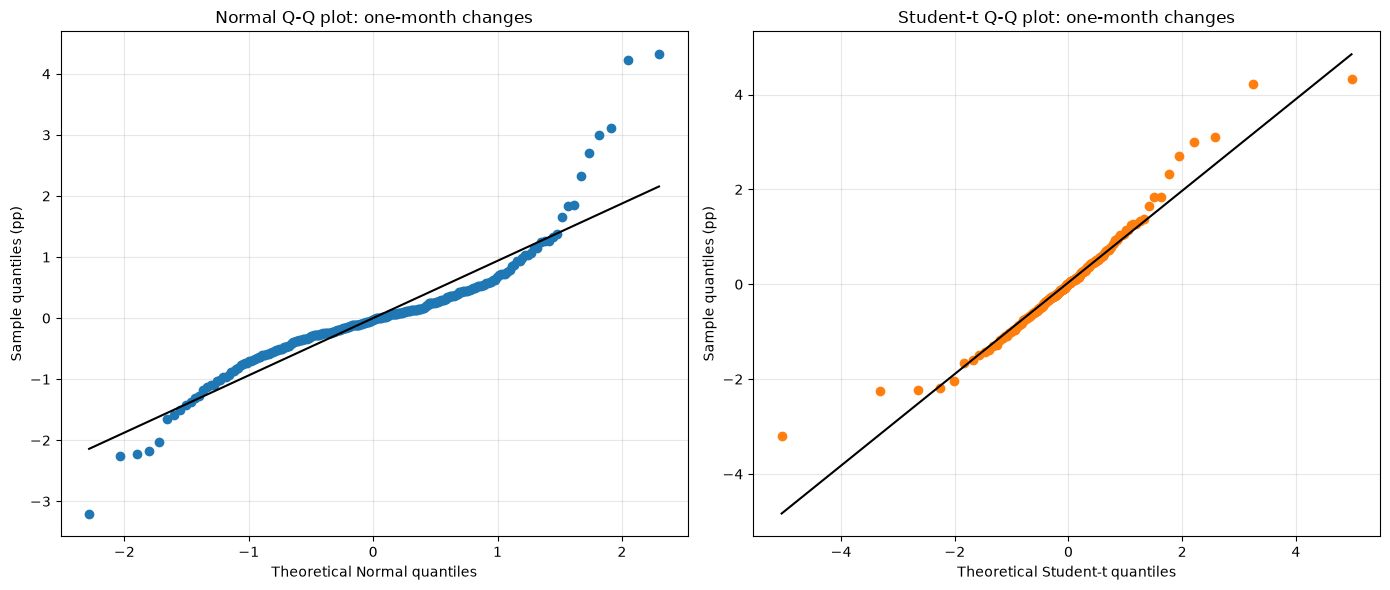

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Normal Q-Q plot
stats.probplot(dS["S_t - S_{t-1}"], dist=stats.norm,
               sparams=(mu_n, sd_n), plot=ax[0])
ax[0].get_lines()[0].set_markerfacecolor("tab:blue")
ax[0].get_lines()[0].set_markeredgecolor("tab:blue")
ax[0].get_lines()[1].set_color("black")
ax[0].set_title("Normal Q-Q plot: one-month changes")
ax[0].set_xlabel("Theoretical Normal quantiles")
ax[0].set_ylabel("Sample quantiles (pp)")
ax[0].grid(alpha=0.3)

# Student-t Q-Q plot
stats.probplot(dS["S_t - S_{t-1}"], dist=stats.t,
               sparams=(nu_t, loc_t, scale_t), plot=ax[1])
ax[1].get_lines()[0].set_markerfacecolor("tab:orange")
ax[1].get_lines()[0].set_markeredgecolor("tab:orange")
ax[1].get_lines()[1].set_color("black")
ax[1].set_title("Student-t Q-Q plot: one-month changes")
ax[1].set_xlabel("Theoretical Student-t quantiles")
ax[1].set_ylabel("Sample quantiles (pp)")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("qq_monthly_normal_t.png", dpi=150)
plt.show()

The red dashed line represents where the points would lie if the empirical distribution perfectly matched the theoretical distribution.The Normal Q-Q plot shows an S-shape: the middle points are flatter than the line, and the tails curve far away from it, especially the large right-tail widenings above +3 pp. The Student-t Q-Q plot sits almost on the line from roughly -2 to +2, confirming it captures the body of the distribution well. The remaining misfit is at the extremes, where the most negative point falls short of the t’s predicted tail and the largest positive points sit above it, hinting at some asymmetry (bigger widenings than tightenings) and an unstable ν estimate.

#CI Bands for 6 month

In [37]:
# ---------- 1. Fit both distributions by maximum likelihood ----------
mu, sd = stats.norm.fit(y_train)
nu, loc, scale = stats.t.fit(y_train)

# ---------- 2. Model comparison with AIC ----------
ll_norm = stats.norm.logpdf(y_train, mu, sd).sum()
ll_t = stats.t.logpdf(y_train, nu, loc, scale).sum()
aic_norm = 2 * 2 - 2 * ll_norm
aic_t = 2 * 3 - 2 * ll_t

# ---------- 3. 90% prediction intervals from the quantile functions ----------
lo_n, hi_n = stats.norm.ppf([0.05, 0.95], mu, sd)
lo_t, hi_t = stats.t.ppf([0.05, 0.95], nu, loc, scale)

# ---------- 4. Width and empirical coverage on the test set ----------
results = []
for name, lo, hi, aic in [("Normal", lo_n, hi_n, aic_norm),
                          ("Student-t", lo_t, hi_t, aic_t)]:
    results.append({"Model": name,
                    "Lower (pp)": round(lo, 3),
                    "Upper (pp)": round(hi, 3),
                    "Width (bps)": round(100 * (hi - lo), 1),
                    "AIC": round(aic, 1)})

print(pd.DataFrame(results))
print(f"Student-t nu = {nu:.2f}, n_train = {len(y_train)}, n_test = {len(y_test)}")

       Model  Lower (pp)  Upper (pp)  Width (bps)     AIC
0     Normal      -3.691       3.675        736.6  1205.5
1  Student-t      -3.399       3.093        649.2  1130.7
Student-t nu = 2.39, n_train = 270, n_test = 36


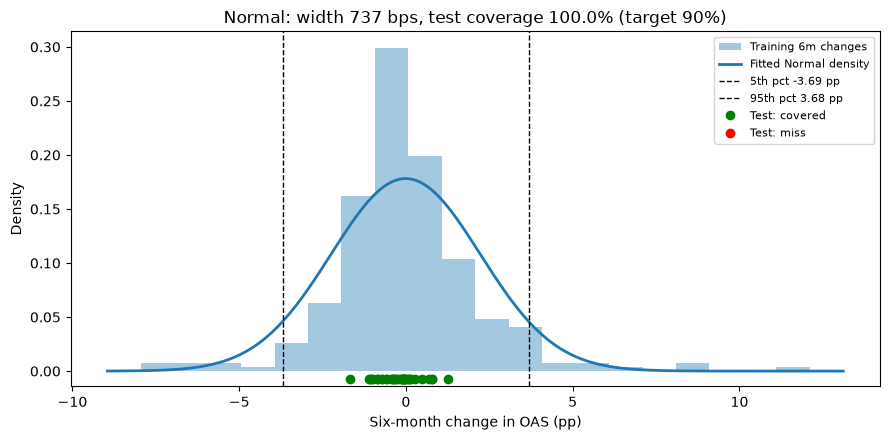

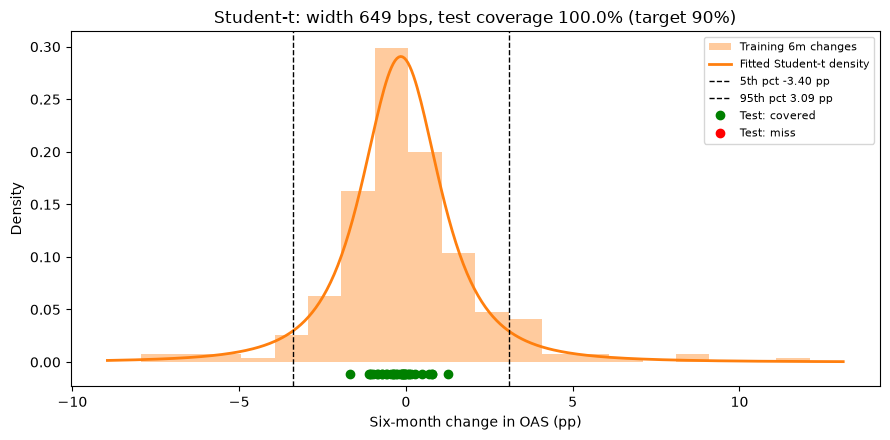

In [38]:
models = [
    ("Normal", stats.norm, (mu, sd), "tab:blue"),
    ("Student-t", stats.t, (nu, loc, scale), "tab:orange"),
]

# x-grid for drawing the fitted density, padded beyond the data
x = np.linspace(min(y_train.min(), y_test.min()) - 1,
                max(y_train.max(), y_test.max()) + 1, 400)

for name, dist, params, colour in models:
    lo, hi = dist.ppf([0.05, 0.95], *params)     # 90% prediction interval
    covered = (y_test >= lo) & (y_test <= hi)     # True where realised change is inside
    coverage = covered.mean()
    width_bps = 100 * (hi - lo)

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.hist(y_train, bins=20, density=True, alpha=0.4, color=colour,
            label="Training 6m changes")
    pdf = dist.pdf(x, *params)
    ax.plot(x, pdf, color=colour, lw=2, label=f"Fitted {name} density")
    ax.axvline(lo, color="black", ls="--", lw=1, label=f"5th pct {lo:.2f} pp")
    ax.axvline(hi, color="black", ls="--", lw=1, label=f"95th pct {hi:.2f} pp")

    # Test points as markers just below the x-axis (green = covered, red = miss)
    rug_y = -0.04 * pdf.max()
    ax.plot(y_test[covered], np.full(covered.sum(), rug_y), "o",
            color="green", ms=6, label="Test: covered")
    ax.plot(y_test[~covered], np.full((~covered).sum(), rug_y), "o",
            color="red", ms=6, label="Test: miss")
    ax.set_ylim(bottom=-0.08 * pdf.max())

    ax.set_xlabel("Six-month change in OAS (pp)")
    ax.set_ylabel("Density")
    ax.set_title(f"{name}: width {width_bps:.0f} bps, "
                 f"test coverage {coverage:.1%} (target 90%)")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(f"direct6m_{name.lower()}.png", dpi=150)
    plt.show()

The Normal interval is wider than the Student-t interval, and it covers every test point.

Width: The 90% interval runs from -3.69 to +3.68 pp, or 737 bps. The Student-t interval was 649 bps. This is the reverse of what you might expect, since the Student-t is supposed to have heavier tails.
Why it’s wider: The Normal’s standard deviation is inflated by the extreme training observations (around -8 and +12 pp). Its 5th and 95th percentiles are set by that spread, so the whole band stretches to accommodate outliers that are rare.
Why the Student-t is narrower: The t-distribution puts more mass in its tails but less near the centre. At the 5th and 95th percentiles, it can give a tighter band than the Normal fitted to the same data.

Fit to the training data

Centre: The fitted Normal peaks at about 0.18, while the histogram peaks near 0.30. The Normal underestimates the concentration of small moves around zero, which is the clearest visual difference from the Student-t curve.
Shoulders: The Normal overstates the density at moderate moves, around ±2 to ±4 pp, where the bars sit below the curve.
Tails: The bars at -8 pp and +12 pp are far outside the curve. Neither distribution captures them well, but the Student-t at least gives a more realistic peak.
Skew: The histogram has more mass on the right (spreads widening) than the left. A symmetric Normal cannot capture this, and neither can the Student-t as fitted here.

Coverage

100% for both models. This does not separate them. The test points cluster between about -1.8 and +1.3 pp, well inside both intervals, so the test period was too calm to challenge either model.
Test set is small and overlapping. The 36 origins represent only about six independent windows, so this coverage says little about calibration.

What this means for the report

Prefer the Student-t on fit, not coverage. Its centre matches the data better and it has a narrower interval, which is consistent with fat tails.
Coverage cannot rank the models here. Add the AIC and the QQ-plot as the main evidence.

The Student-t interval is wide, and it covers every test point.

Width: The 90% interval runs from -3.40 pp to +3.09 pp, which is 649 bps. That is a wide band for a six-month move, driven by the fat tails in the training data.
Coverage: All test points (green) fall inside the band, so coverage is 100% against a 90% target. This does not show the model is well calibrated. It shows the interval is too wide for 2023–2025.
Test points are tightly clustered: They sit between about -1.8 and +1.3 pp, a much narrower range than the training data. The 2023–2025 period was calmer, so the training-period tails are overstating typical risk for this window.
Small test set: If the 36 origins overlap, they represent only about six independent six-month windows. 100% coverage from so few independent windows is not strong evidence either way.

Fit to the training data

Centre: The fitted curve peaks near 0.29, close to the tallest histogram bar. The Student-t captures the concentration of small moves around zero well.
Tails: The extreme bins reach about -8 pp and +12 pp, and the curve places little mass there. Check the dates of these outliers. They are likely the 2008 and 2020 stress episodes. The Student-t is designed to accommodate such events, but the curve still underweights the far right tail.
Right tail: The bars around +2 to +4 pp sit at or slightly above the curve. This suggests spreads widen more sharply than they tighten, which the symmetric Student-t cannot fully capture.
Sample size: With only about 45 non-overlapping observations, the histogram is coarse, and the estimate of the degrees of freedom (ν) is uncertain.

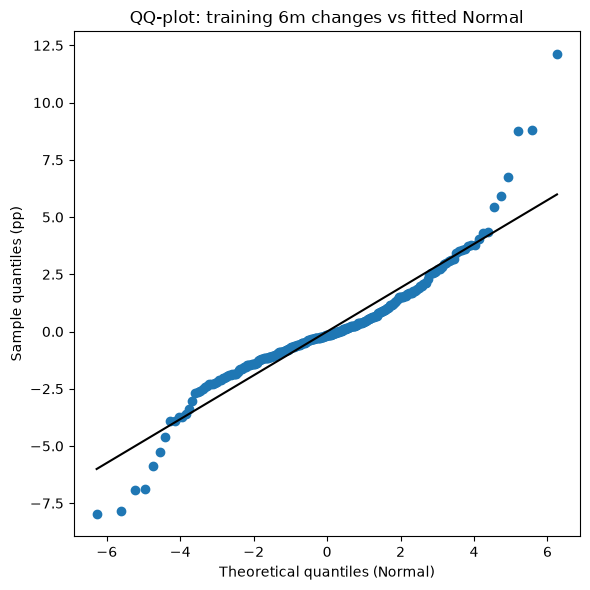

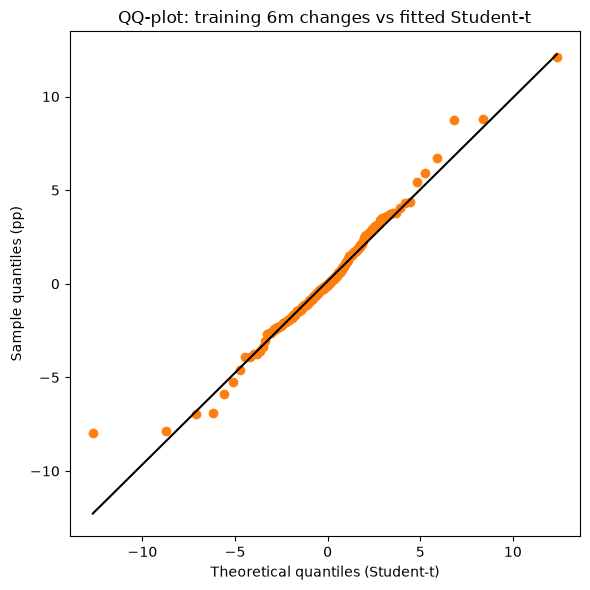

In [39]:
for name, dist, params, colour in models:
    fig, ax = plt.subplots(figsize=(6, 6))
    stats.probplot(y_train, dist=dist, sparams=params, plot=ax)
    ax.get_lines()[0].set_markerfacecolor(colour)
    ax.get_lines()[0].set_markeredgecolor(colour)
    ax.get_lines()[1].set_color("black")
    ax.set_title(f"QQ-plot: training 6m changes vs fitted {name}")
    ax.set_xlabel(f"Theoretical quantiles ({name})")
    ax.set_ylabel("Sample quantiles (pp)")
    plt.tight_layout()
    plt.savefig(f"qq_{name.lower()}.png", dpi=150)
    plt.show()

#Model

## Ridge regression (alpha chosen by time-series CV on the training window)

In [40]:
X_train = X_train.drop(columns=["Month"])
X_test = X_test.drop(columns=["Month"])

In [41]:
pipe = Pipeline([
    ("scale", StandardScaler()),
    ("ridge", RidgeCV(alphas=np.logspace(-2, 3, 30), # alpha from 0.01 to 1000.
                      cv=TimeSeriesSplit(n_splits=5, gap=6),
                      scoring="neg_mean_absolute_error")),
])

# Exclude 'Month' from predictors during training
pipe.fit(X_train, y_train)
print("chosen alpha:", np.round(pipe.named_steps["ridge"].alpha_,4))
print(dict(zip(X_train.columns, pipe.named_steps["ridge"].coef_)))

chosen alpha: 452.0354
{'S_t': np.float64(-0.3351477059393881), 'S_t - S_{t-1}': np.float64(-0.01877608679757548), 'GCI_yoy_L1': np.float64(0.18445044564024285), 'Fed_Rate%_L1': np.float64(0.1507064175900876), 'Unemp_Rate%_L1': np.float64(-0.13332035615710394), 'CPI_yoy_L1': np.float64(0.13492018154767552)}


In [42]:
pred_ridge = pipe.predict(X_test)
pred_naive = np.zeros(len(y_test))       # no-change forecast: S_{t+6} = S_t

print("Ridge MAE:", np.round(mae(y_test, pred_ridge),4))
print("Naive MAE:", np.round(mae(y_test, pred_naive),4))

Ridge MAE: 0.9047
Naive MAE: 0.4958


Systematic Bias

The mean-reversion term pulls toward the training-period average spread. The training sample (2000 to 2022) includes the 2008 and 2020 spikes, so its average is high. The 2023 to 2025 test period had persistently low spreads, below that average. The model sees S_t as “low” and predicts widening, but spreads stayed tight.

In [43]:
resid = y_test - pred_ridge
print("mean forecast:", pred_ridge.mean(), " mean actual:", y_test.mean())
print("bias (mean residual):", resid.mean())

mean forecast: 0.6234876342689191  mean actual: -0.2386111111111111
bias (mean residual): -0.8620987453800302


In [44]:
print("intercept:", round(pipe.named_steps["ridge"].intercept_, 4),
      " mean of y_train:", round(y_train.mean(), 4))

intercept: -0.008  mean of y_train: -0.008


If the intercept is close to the training mean,the forecast reflects the average of past crises more than the current spread.

# 6 Month Simulation

In [45]:
train_dS = merged_df.loc[merged_df["Month"] <= "2022-06-01", "S_t - S_{t-1}"].dropna()

mu_m, sd_m = stats.norm.fit(train_dS)             # Normal: MLE of mean and sd
nu_m, loc_m, scale_m = stats.t.fit(train_dS)
ll_n_m = stats.norm.logpdf(train_dS, mu_m, sd_m).sum()
ll_t_m = stats.t.logpdf(train_dS, nu_m, loc_m, scale_m).sum()
print("Monthly AIC  Normal:", round(2*2 - 2*ll_n_m, 1),
      " Student-t:", round(2*3 - 2*ll_t_m, 1))

# ---------- 2. Simulate six-month changes as sums of 6 monthly draws ----------
# Each row is one simulated 6-month path; summing its 6 draws gives one 6-month change
rng = np.random.default_rng(603)
N, H = 200_000, 6
sim_n = rng.normal(mu_m, sd_m, size=(N, H)).sum(axis=1)
sim_t = stats.t.rvs(nu_m, loc=loc_m, scale=scale_m,
                    size=(N, H), random_state=rng).sum(axis=1)

# ---------- 3. Direct fit to six-month changes (for comparison) ----------
mu6, sd6 = stats.norm.fit(y_train)
nu6, loc6, scale6 = stats.t.fit(y_train)

# ---------- 4. 90% bands and test coverage for each method ----------
def band_summary(name, lo, hi):
    cov = ((y_test >= lo) & (y_test <= hi)).mean()     # share of test outcomes inside band
    return {"Method": name,
            "Lower (pp)": round(lo, 3),
            "Upper (pp)": round(hi, 3),
            "Width (bps)": round(100 * (hi - lo), 1),  # 1 pp = 100 bps
            "Test coverage": round(cov, 3)}

rows = [
    band_summary("Direct Normal",      *stats.norm.ppf([0.05, 0.95], mu6, sd6)),
    band_summary("Direct Student-t",   *stats.t.ppf([0.05, 0.95], nu6, loc6, scale6)),
    band_summary("Simulated Normal",   *np.percentile(sim_n, [5, 95])),
    band_summary("Simulated Student-t", *np.percentile(sim_t, [5, 95])),
]
print(pd.DataFrame(rows))


# Variance ratio: VR = Var(6-month change) / (6 * Var(1-month change))
#     VR near 1 supports the iid assumption behind the simulation
vr = y_train.var() / (6 * train_dS.var())
print("Variance ratio:", round(vr, 3))

Monthly AIC  Normal: 662.1  Student-t: 556.7
                Method  Lower (pp)  Upper (pp)  Width (bps)  Test coverage
0        Direct Normal      -3.691       3.675        736.6            1.0
1     Direct Student-t      -3.399       3.093        649.2            1.0
2     Simulated Normal      -3.237       3.324        656.2            1.0
3  Simulated Student-t      -3.604       3.190        679.5            1.0
Variance ratio: 1.247


In [46]:
#AIC on the monthly fit
ll_n_m = stats.norm.logpdf(train_dS, mu_m, sd_m).sum()
ll_t_m = stats.t.logpdf(train_dS, nu_m, loc_m, scale_m).sum()
print("Monthly AIC  Normal:", round(2*2 - 2*ll_n_m, 1),
      " Student-t:", round(2*3 - 2*ll_t_m, 1))

Monthly AIC  Normal: 662.1  Student-t: 556.7


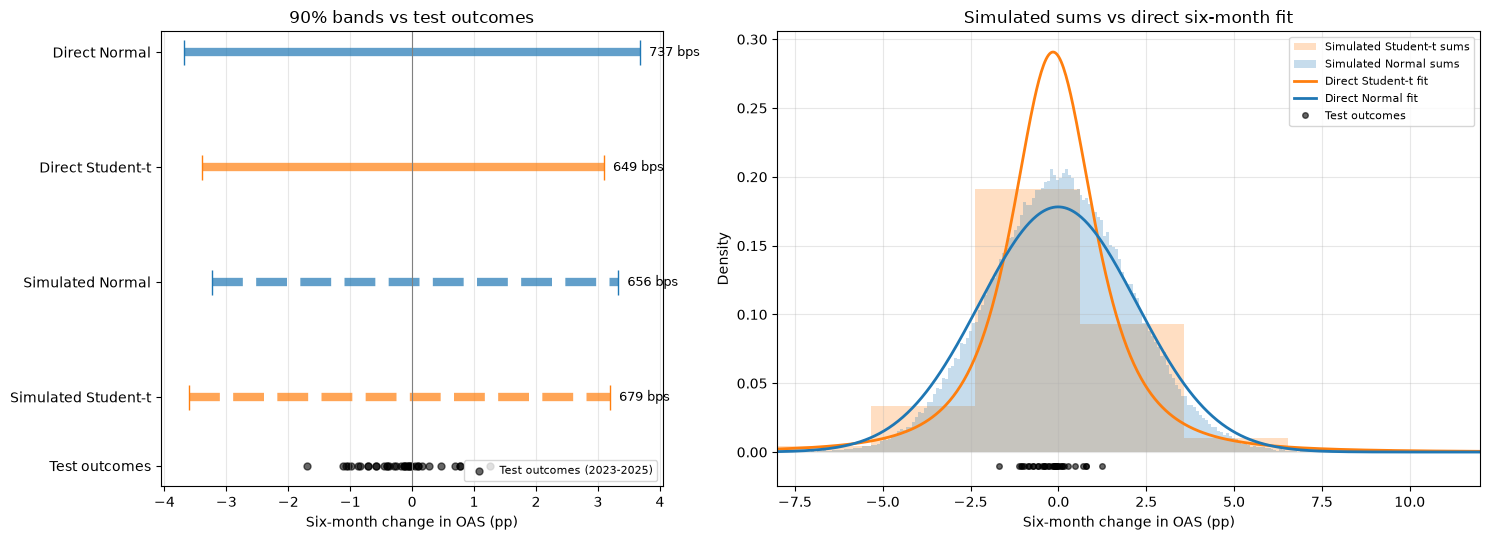

In [47]:
# ---------- Bands from the previous cell ----------
bands = {
    "Direct Normal":        (stats.norm.ppf([0.05, 0.95], mu6, sd6),          "tab:blue",   "-"),
    "Direct Student-t":     (stats.t.ppf([0.05, 0.95], nu6, loc6, scale6),    "tab:orange", "-"),
    "Simulated Normal":     (np.percentile(sim_n, [5, 95]),                   "tab:blue",   "--"),
    "Simulated Student-t":  (np.percentile(sim_t, [5, 95]),                   "tab:orange", "--"),
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5),
                               gridspec_kw={"width_ratios": [1, 1.4]})

# ---------- Left panel: the four 90% bands as horizontal lines ----------
for i, (name, ((lo, hi), colour, ls)) in enumerate(bands.items()):
    y_pos = len(bands) - i                            # stack the bands top to bottom
    ax1.hlines(y_pos, lo, hi, colors=colour, linestyles=ls, lw=6, alpha=0.7)
    ax1.plot([lo, hi], [y_pos, y_pos], "|", color=colour, ms=18)
    ax1.text(hi + 0.15, y_pos, f"{100*(hi-lo):.0f} bps", va="center", fontsize=9)

# Test outcomes as a strip plot below the bands
rug_y = 0.4
ax1.scatter(y_test, np.full(len(y_test), rug_y), s=25, color="black",
            alpha=0.6, label="Test outcomes (2023-2025)")

ax1.axvline(0, color="grey", lw=0.8)
ax1.set_yticks(list(range(len(bands), 0, -1)) + [rug_y])
ax1.set_yticklabels(list(bands.keys()) + ["Test outcomes"])
ax1.set_xlabel("Six-month change in OAS (pp)")
ax1.set_title("90% bands vs test outcomes")
ax1.grid(axis="x", alpha=0.3)
ax1.legend(loc="lower right", fontsize=8)

# ---------- Right panel: densities of the simulated and direct six-month distributions ----------
x = np.linspace(-8, 12, 600)
ax2.hist(sim_t, bins=200, density=True, alpha=0.25, color="tab:orange",
         label="Simulated Student-t sums")
ax2.hist(sim_n, bins=200, density=True, alpha=0.25, color="tab:blue",
         label="Simulated Normal sums")
ax2.plot(x, stats.t.pdf(x, nu6, loc6, scale6), color="tab:orange", lw=2,
         label="Direct Student-t fit")
ax2.plot(x, stats.norm.pdf(x, mu6, sd6), color="tab:blue", lw=2,
         label="Direct Normal fit")
ax2.plot(y_test, np.zeros(len(y_test)) - 0.01, "o", color="black", alpha=0.6,
         ms=4, label="Test outcomes")
ax2.set_xlim(-8, 12)
ax2.set_xlabel("Six-month change in OAS (pp)")
ax2.set_ylabel("Density")
ax2.set_title("Simulated sums vs direct six-month fit")
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("band_comparison.png", dpi=150)
plt.show()

The 2023–2025 test outcomes fall roughly between −1.7 and +1.3 pp, about 300 bps in total. All bands are wide relative to the outcomes. The bands are about 650–740 bps wide. The training data (2000–2022) includes the 2008 financial crisis and COVID, when spreads moved by several hundred bps within six months. Those extreme moves fatten the tails. The test period (2023–2025) was calm, so it sits well inside the bands.



*   Direct fit vs. simulation. The simulated bands (656 and 679 bps) are built by summing six simulated monthly changes, assuming each month is independent. The direct fits are estimated from six-month changes themselves.
*   The simulated Normal band is narrower than the direct Normal band (656 < 737). If monthly changes were independent, the variance of the six-month sum would be 6σ², and the two methods would agree.
*   The gap suggests the six-month changes are more volatile than the monthly changes imply, which points to positive autocorrelation (spreads trend in the same direction over consecutive months). The independence assumption therefore understates risk. This matches the weakness flagged in the proposal and supports using a block bootstrap.

                  Method  Width (bps)  Test coverage  MAE of centre
0  Ridge band (residual)        573.7            1.0          0.905
1  Direct Student-t band        649.2            1.0          0.496


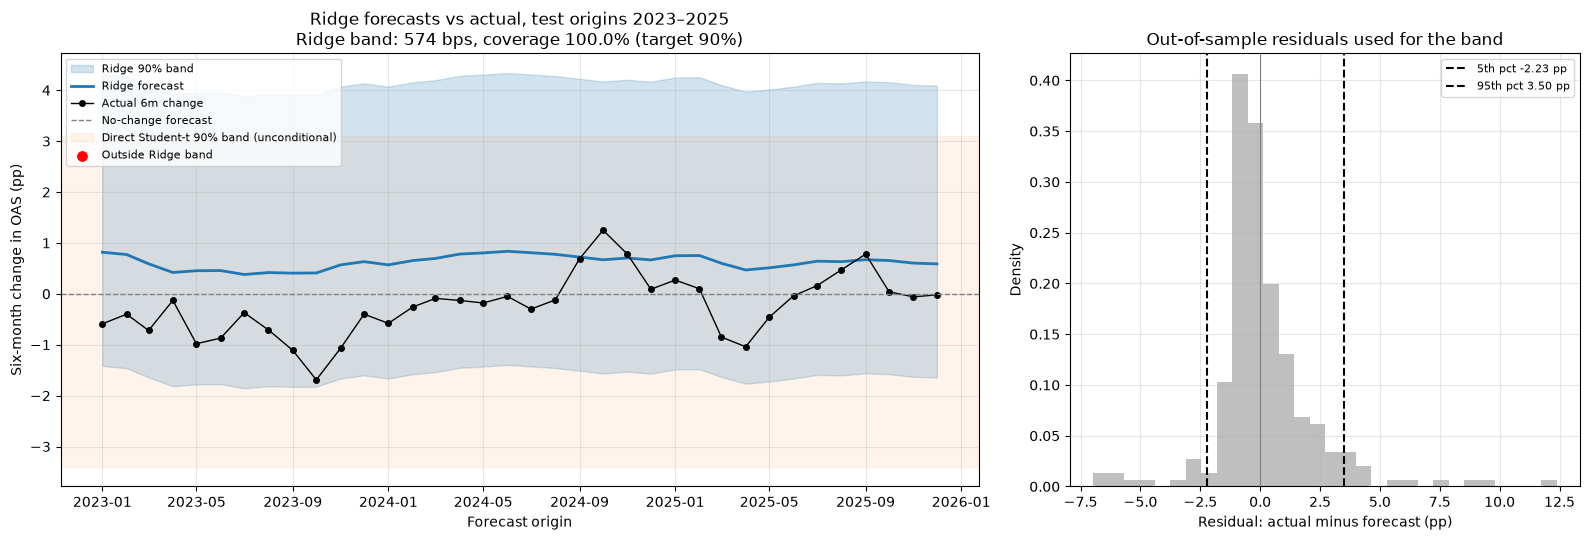

In [48]:
# ---------- 1. Band width from out-of-sample training residuals ----------
# Residual for each origin: e_i = y_i - yhat_i
# In-sample residuals are too small (the model has already seen those points),
# so we get out-of-sample predictions with the same time-series CV folds.
alpha_best = pipe.named_steps["ridge"].alpha_
cv = TimeSeriesSplit(n_splits=5, gap=6)

oof_pred = pd.Series(np.nan, index=X_train.index)
for tr_idx, va_idx in cv.split(X_train):
    m = Pipeline([("scale", StandardScaler()),
                  ("ridge", Ridge(alpha=alpha_best))])     # fixed alpha, no re-tuning
    m.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    oof_pred.iloc[va_idx] = m.predict(X_train.iloc[va_idx])

resid_oof = (y_train - oof_pred).dropna()
q_lo, q_hi = np.quantile(resid_oof, [0.05, 0.95])        # 90% residual band

# ---------- 2. Ridge 90% band around each forecast ----------
# Band: yhat + q_lo to yhat + q_hi
p_ridge = np.asarray(pred_ridge)
y_true = np.asarray(y_test)
ridge_lo, ridge_hi = p_ridge + q_lo, p_ridge + q_hi
covered = (y_true >= ridge_lo) & (y_true <= ridge_hi)    # coverage = share inside band
ridge_cov = covered.mean()
ridge_width = 100 * (q_hi - q_lo)                        # pp to bps

# Direct unconditional band (Student-t, six-month fit), for comparison
d_lo, d_hi = stats.t.ppf([0.05, 0.95], nu6, loc6, scale6)

summary = pd.DataFrame([
    {"Method": "Ridge band (residual)", "Width (bps)": round(ridge_width, 1),
     "Test coverage": round(ridge_cov, 3),
     "MAE of centre": round(mae(y_true, p_ridge), 3)},
    {"Method": "Direct Student-t band", "Width (bps)": round(100 * (d_hi - d_lo), 1),
     "Test coverage": round(((y_true >= d_lo) & (y_true <= d_hi)).mean(), 3),
     "MAE of centre": round(mae(y_true, np.zeros_like(y_true)), 3)},  # centre = 0 (naive)
])
print(summary)

# ---------- 3. Plot ----------
dates = merged_df.loc[test_mask, "Month"].values

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5),
                               gridspec_kw={"width_ratios": [1.8, 1]})

# Left: forecasts, bands, actuals over the 36 test origins
ax1.fill_between(dates, ridge_lo, ridge_hi, color="tab:blue", alpha=0.2,
                 label="Ridge 90% band")
ax1.plot(dates, p_ridge, color="tab:blue", lw=2, label="Ridge forecast")
ax1.plot(dates, y_true, "o-", color="black", ms=4, lw=1, label="Actual 6m change")
ax1.axhline(0, color="grey", ls="--", lw=1, label="No-change forecast")
ax1.axhspan(d_lo, d_hi, color="tab:orange", alpha=0.08,
            label="Direct Student-t 90% band (unconditional)")
ax1.scatter(dates[~covered], y_true[~covered], color="red", s=45,
            zorder=5, label="Outside Ridge band")
ax1.set_title(f"Ridge forecasts vs actual, test origins 2023–2025\n"
              f"Ridge band: {ridge_width:.0f} bps, coverage {ridge_cov:.1%} (target 90%)")
ax1.set_ylabel("Six-month change in OAS (pp)")
ax1.set_xlabel("Forecast origin")
ax1.grid(alpha=0.3)
ax1.legend(fontsize=8, loc="upper left")

# Right: where the band comes from (out-of-sample training residuals)
ax2.hist(resid_oof, bins=30, density=True, alpha=0.5, color="grey")
ax2.axvline(q_lo, color="black", ls="--", label=f"5th pct {q_lo:.2f} pp")
ax2.axvline(q_hi, color="black", ls="--", label=f"95th pct {q_hi:.2f} pp")
ax2.axvline(0, color="grey", lw=0.8)
ax2.set_title("Out-of-sample residuals used for the band")
ax2.set_xlabel("Residual: actual minus forecast (pp)")
ax2.set_ylabel("Density")
ax2.grid(alpha=0.3)
ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig("ridge_vs_bands.png", dpi=150)
plt.show()

The forecast is biased upward. The Ridge line sits around +0.4 to +1.2 pp for almost the entire period, while most actual changes are negative. The average forecast is roughly +0.6 pp and the average actual is roughly −0.3 pp. That gap is a bias of about 0.9 pp.
The forecast barely moves. It stays in a narrow range, so it is not responding much to the actual ups and downs. Ridge shrinks predictions toward the training average. If the training period (2000–2022) contains many spread-widening episodes, that average is positive, and the model drifts toward it.